In [1]:
import numpy as np
import pandas as pd
from pulp import LpProblem, LpMinimize, LpVariable, lpSum, LpBinary, LpStatus, value
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
def logistic(x, floor, ceil, steep, mid):
        return floor + (ceil - floor) / (1.0 + np.exp(-steep * (x - mid)))

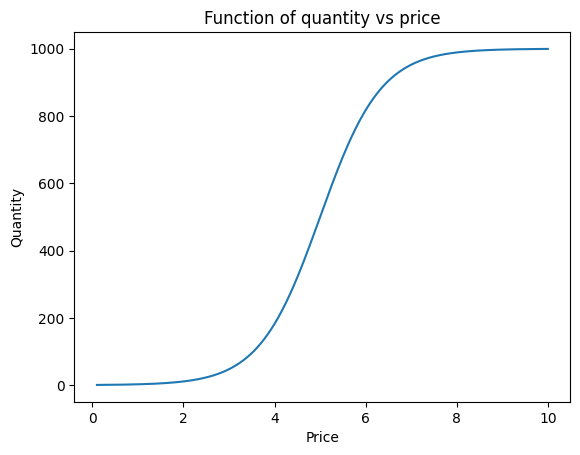

In [7]:
x_curve = np.linspace(0.1, 10, 1000)
y_curve = logistic(x_curve, 0, 1000, 1.5, 5)
plt.plot(x_curve, y_curve)
plt.xlabel("Price")
plt.ylabel("Quantity")
plt.title("Function of quantity vs price")
plt.show()

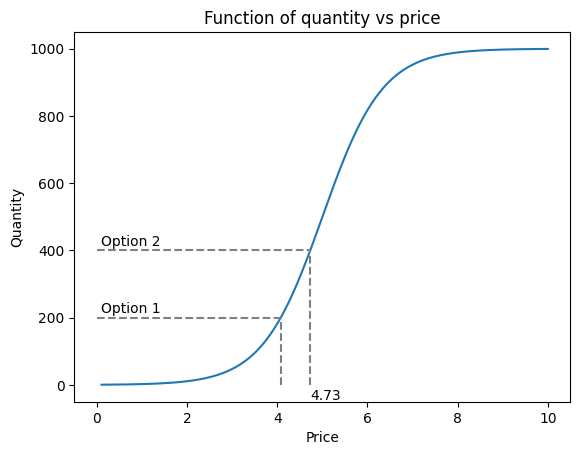

In [ ]:
x_curve = np.linspace(0.1, 10, 1000)
y_curve = logistic(x_curve, 0, 1000, 1.5, 5)

plt.plot(x_curve, y_curve)

for qty in [200, 400]:
    price = 5 - np.log(1000 / qty - 1) / 1.5

    plt.hlines(qty, xmin=0, xmax=price, colors="gray", linestyles="dashed")

    plt.vlines(price, ymin=0, ymax=qty, colors="gray", linestyles="dashed")

    if qty == 400:
        plt.text(price, -45, f"{price:.2f}", ha="left")

    label = "Option 1" if qty == 200 else "Option 2"
    plt.text(0.1, qty + 15, label, ha="left")

plt.xlabel("Price")
plt.ylabel("Quantity")
plt.title("Function of quantity vs price")
plt.show()

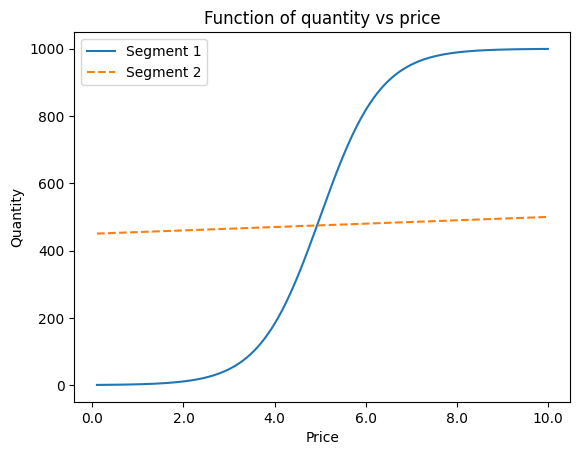

In [ ]:
import matplotlib.ticker as mtick

x_curve = np.linspace(0.1, 10, 1000)
y_curve = logistic(x_curve, 0, 1000, 1.5, 5)

y_line = 450 + 5 * x_curve

fig, ax = plt.subplots()

ax.plot(x_curve, y_curve, label="Segment 1")
ax.plot(x_curve, y_line, "--", label="Segment 2")

ax.xaxis.set_major_formatter(
    mtick.FormatStrFormatter('%.1f')
)

plt.xlabel("Price")
plt.ylabel("Quantity")
plt.title("Function of quantity vs price")
plt.legend()

plt.show()

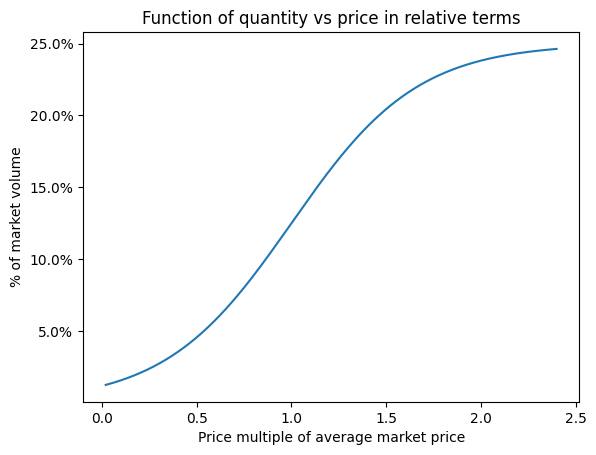

In [5]:
import matplotlib.ticker as mtick

x_curve = np.linspace(0.1/5, 12/5, 1000)
y_curve = logistic(x_curve, 0, 0.25, 3, 1)

fig, ax = plt.subplots()

ax.plot(x_curve, y_curve)

# x-axis: 1 decimal
ax.xaxis.set_major_formatter(
    mtick.FormatStrFormatter('%.1f')
)

# y-axis: percent
ax.yaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=1)
)

plt.xlabel("Price multiple of average market price")
plt.ylabel("% of market volume")
plt.title("Function of quantity vs price in relative terms")

plt.show()

In [ ]:
def build_options(day_params, bid_min=0.1, bid_max=5.0, n_points=500):
    rows = []

    for day, p in day_params.items():
        bid_grid = np.linspace(bid_min, bid_max, n_points)

        for i, price in enumerate(bid_grid):
            qty = logistic(
                price,
                p["floor"],
                p["ceil"],
                p["steep"],
                p["mid"]
            )

            qty = max(0.0, float(qty))
            cost = price * qty

            rows.append({
                "day": day,
                "option_id": f"{day}_opt_{i}",
                "price": float(price),
                "qty": qty,
                "cost": cost
            })

    return pd.DataFrame(rows)


def solve_bid_milp(options_df, target_qty):
    model = LpProblem("daily_bid_optimization", LpMinimize)

    option_ids = options_df["option_id"].tolist()

    z = {
        oid: LpVariable(f"z_{oid}", cat=LpBinary)
        for oid in option_ids
    }

    # objective: minimize total cost
    model += lpSum(
        row.cost * z[row.option_id]
        for row in options_df.itertuples(index=False)
    )

    # at least one option per day
    for day in options_df["day"].unique():
        day_option_ids = options_df.loc[options_df["day"] == day, "option_id"].tolist()
        model += lpSum(z[oid] for oid in day_option_ids) <= 1, f"one_option_{day}"

    # total quantity must meet target
    model += lpSum(
        row.qty * z[row.option_id]
        for row in options_df.itertuples(index=False)
    ) >= target_qty, "target_quantity"

    model.solve()

    status = LpStatus[model.status]

    chosen = options_df[
        options_df["option_id"].map(lambda oid: value(z[oid]) > 0.5)
    ].copy()

    chosen = chosen.sort_values("day").reset_index(drop=True)

    result = {
        "status": status,
        "total_qty": chosen["qty"].sum(),
        "total_cost": chosen["cost"].sum(),
        "chosen_options": chosen
    }

    return result

In [ ]:
if __name__ == "__main__":
    day_params = {
        "day_1": {"floor": 0, "ceil": 1000, "steep": 3.0, "mid": 2.0},
        "day_2": {"floor": 0, "ceil": 1000, "steep": 1, "mid": 4.0},
        "day_3": {"floor": 0, "ceil": 1000, "steep": 0.7, "mid": 6.0},
    }

    target_qty = 1700

    options_df = build_options(
        day_params=day_params,
        bid_min=0.1,
        bid_max=10.0,
        n_points=500
    )

    result = solve_bid_milp(options_df, target_qty)

    print("Status:", result["status"])
    print("Total qty:", result["total_qty"])
    print("Total cost:", result["total_cost"])
    print()
    print(result["chosen_options"][["day", "price", "qty", "cost"]])

Status: Optimal
Total qty: 1700.1280794905174
Total cost: 5876.858169147138

     day     price         qty         cost
0  day_1  2.758517  906.831849  2501.511102
1  day_2  4.186974  546.607785  2288.632555
2  day_3  4.405210  246.688446  1086.714512


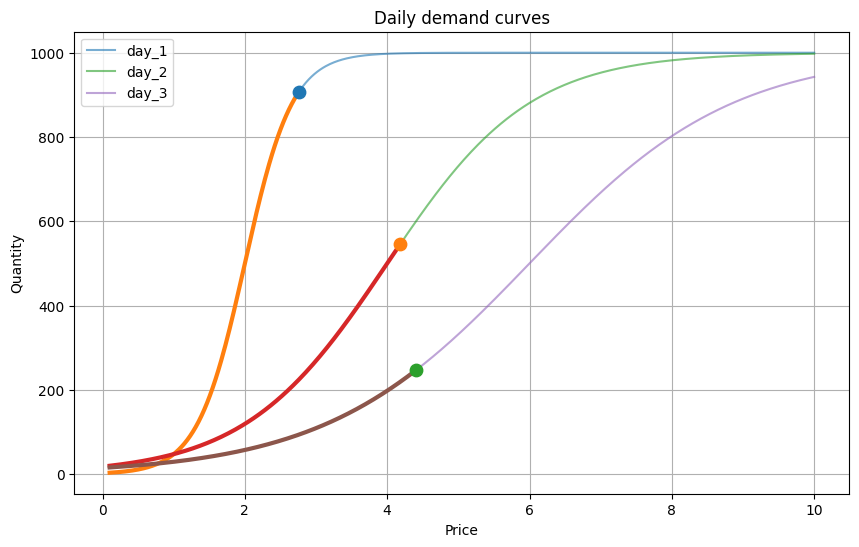

In [ ]:
def plot_all_daily_curves_with_selected_left(options_df, chosen_df):
    plt.figure(figsize=(10, 6))

    days = sorted(options_df["day"].unique())

    for day in days:
        curve = options_df[options_df["day"] == day].sort_values("price").copy()

        plt.plot(
            curve["price"],
            curve["qty"],
            alpha=0.6,
            label=f"{day}"
        )

        selected = chosen_df[chosen_df["day"] == day]

        if len(selected) > 0:
            sel_price = selected["price"].iloc[0]
            sel_qty = selected["qty"].iloc[0]

            left_curve = curve[curve["price"] <= sel_price]
            plt.plot(
                left_curve["price"],
                left_curve["qty"],  
                linewidth=3
            )

            plt.scatter(
                [sel_price],
                [sel_qty],
                s=80,
                zorder=5
            )

    plt.xlabel("Price")
    plt.ylabel("Quantity")
    plt.legend()
    plt.title("Daily demand curves")
    plt.grid(True)
    plt.show()

plot_all_daily_curves_with_selected_left(options_df, result['chosen_options'])

In [97]:
if __name__ == "__main__":
    day_params = {
        "day_1": {"floor": 0, "ceil": 1000, "steep": 3.0, "mid": 2.0},
        "day_2": {"floor": 0, "ceil": 1000, "steep": 1, "mid": 4.0},
        "day_3": {"floor": 0, "ceil": 1000, "steep": 0.7, "mid": 6.0},
    }

    target_qty = 2000

    options_df = build_options(
        day_params=day_params,
        bid_min=0.1,
        bid_max=10.0,
        n_points=500
    )

    result2 = solve_bid_milp(options_df, target_qty)

    print("Status:", result2["status"])
    print("Total qty:", result2["total_qty"])
    print("Total cost:", result2["total_cost"])
    print()
    print(result2["chosen_options"][["day", "price", "qty", "cost"]])

Status: Optimal
Total qty: 2000.044288652825
Total cost: 7985.415009549276

     day     price         qty         cost
0  day_1  2.877555  932.934506  2684.570454
1  day_2  4.682966  664.400341  3111.364161
2  day_3  5.436874  402.709442  2189.480394


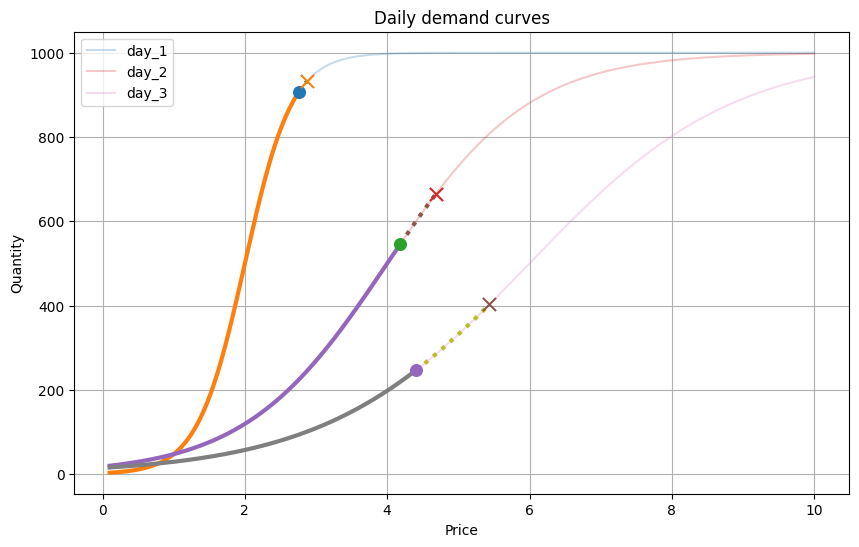

In [ ]:
plt.figure(figsize=(10, 6))

days = sorted(options_df["day"].unique())

for day in days:
    curve = options_df[options_df["day"] == day].sort_values("price").copy()

    selected1 = result["chosen_options"][result["chosen_options"]["day"] == day]
    selected2 = result2["chosen_options"][result2["chosen_options"]["day"] == day]

    plt.plot(
        curve["price"],
        curve["qty"],
        alpha=0.25,
        label=f"{day}"
    )

    if len(selected1) > 0:
        p1 = selected1["price"].iloc[0]
        q1 = selected1["qty"].iloc[0]

        left_curve = curve[curve["price"] <= p1]
        plt.plot(
            left_curve["price"],
            left_curve["qty"],
            linewidth=3
        )

        plt.scatter([p1], [q1], s=70, zorder=5, marker="o")

    if len(selected1) > 0 and len(selected2) > 0:
        p2 = selected2["price"].iloc[0]
        q2 = selected2["qty"].iloc[0]

        middle_curve = curve[
            (curve["price"] >= p1) &
            (curve["price"] <= p2)
        ]

        plt.plot(
            middle_curve["price"],
            middle_curve["qty"],
            linewidth=3,
            linestyle=":"
        )

        plt.scatter([p2], [q2], s=90, zorder=6, marker="x")

    elif len(selected2) > 0:
        p2 = selected2["price"].iloc[0]
        q2 = selected2["qty"].iloc[0]

        left_curve_2 = curve[curve["price"] <= p2]
        plt.plot(
            left_curve_2["price"],
            left_curve_2["qty"],
            linewidth=3,
            linestyle=":"
        )

        plt.scatter([p2], [q2], s=90, zorder=6, marker="x")

plt.xlabel("Price")
plt.ylabel("Quantity")
plt.title("Daily demand curves")
plt.grid(True)
plt.legend()
plt.show()

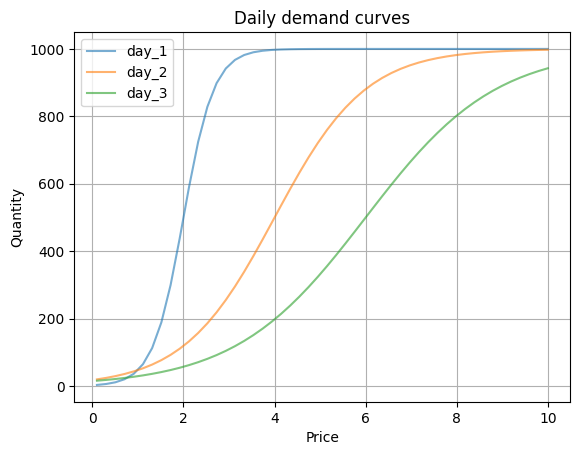

In [ ]:
days = sorted(options_df["day"].unique())

for day in days:
    curve = options_df[options_df["day"] == day].sort_values("price").copy()

    plt.plot(
        curve["price"],
        curve["qty"],
        alpha=0.6,
        label=f"{day}"
    )

plt.xlabel("Price")
plt.ylabel("Quantity")
plt.legend()
plt.title("Daily demand curves")
plt.grid(True)
plt.show()

In [26]:
days

['day_1', 'day_2', 'day_3']

day_1
day_2
day_3


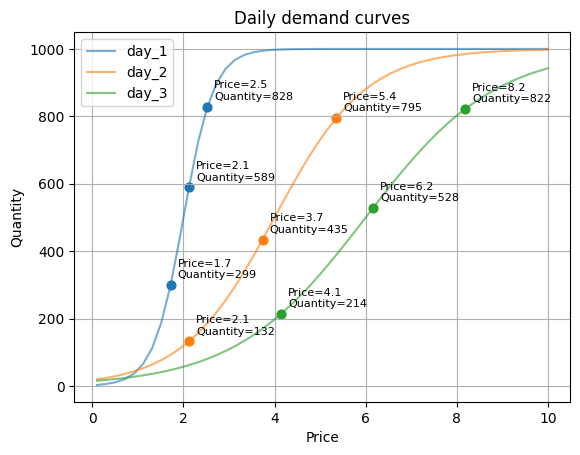

In [ ]:
days = sorted(options_df["day"].unique())

for day in days:
    curve = (
        options_df[options_df["day"] == day]
        .sort_values("price")
        .copy()
    )

    plt.plot(
        curve["price"],
        curve["qty"],
        alpha=0.6,
        label=f"{day}"
    )

    print(day)
    if day == "day_1":
        sample_points = curve.iloc[round(len(curve)*0.15) : round(len(curve)*0.27) : max(1, len(curve)//20)]
    elif day == "day_2":
        sample_points = curve.iloc[round(len(curve)*0.2) : round(len(curve)*0.6) : max(1, len(curve)//6)]
    else:
        sample_points = curve.iloc[round(len(curve)*0.4) : round(len(curve)*0.9) : max(1, len(curve)//5)]

    plt.scatter(
        sample_points["price"],
        sample_points["qty"],
        s=40
    )

    for _, row in sample_points.iterrows():
        plt.annotate(
            f'Price={row["price"]:.1f}\nQuantity={row["qty"]:.0f}',
            (row["price"], row["qty"]),
            textcoords="offset points",
            xytext=(5, 5),
            fontsize=8
        )

plt.xlabel("Price")
plt.ylabel("Quantity")
plt.legend()
plt.title("Daily demand curves")
plt.grid(True)
plt.show()

<br>
<br>


## Time series example

In [2]:
import matplotlib.ticker as mtick

df = pd.read_csv("data/electricity_demand.csv")
df

,Region Code,Timestamp (Hour Ending),CAL Demand (MWh),CAR Demand (MWh),CENT Demand (MWh),FLA Demand (MWh),MIDA Demand (MWh),MIDW Demand (MWh),NE Demand (MWh),NW Demand (MWh),NY Demand (MWh),SE Demand (MWh),SW Demand (MWh),TEN Demand (MWh),TEX Demand (MWh)
0,US48,"5/16/2025, Eastern Time",724914,675884.000000,780660,847059,2295679,1976049,282417,937068.0,381591,727549.0,313487.08,480546,1469320
1,US48,"5/17/2025, Eastern Time",667758,635007.000000,734402,846680,2039348,1745067,278055,882091.0,371042,671767.0,308675.45,448723,1452414
2,US48,"5/18/2025, Eastern Time",625023,606297.000000,810262,863413,1898130,1701938,252890,869372.0,352067,633130.0,295483.10,431280,1419286
3,US48,"5/19/2025, Eastern Time",717810,621339.000000,763946,898034,2007943,1872410,254658,922263.0,352986,712496.0,311920.58,473449,1466753
4,US48,"5/20/2025, Eastern Time",777017,642211.000000,811981,913146,1973496,1911973,263754,934808.0,345213,756869.0,331701.39,475205,1440654
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,US48,"5/12/2026, Eastern Time",780780,518097.000000,800225,788567,2017582,1821612,247619,958279.0,323693,NaN,379403.41,414095,1333703
362,US48,"5/13/2026, Eastern Time",739049,538677.000000,816053,786769,2024117,1806672,277535,945790.0,351045,NaN,361492.61,421525,1409524
363,US48,"5/14/2026, Eastern Time",747048,537128.000000,824783,800792,2008756,1819915,284304,924485.0,356595,NaN,343557.71,399170,1445583
364,US48,"5/15/2026, Eastern Time",761665,517024.000000,862520,793574,2003519,1858242,266992,931835.0,337247,NaN,322957.33,408476,1424139


In [17]:
df.columns

Index(['Region Code', 'Timestamp (Hour Ending)', 'CAL Demand (MWh)',
       'CAR Demand (MWh)', 'CENT Demand (MWh)', 'FLA Demand (MWh)',
       'MIDA Demand (MWh)', 'MIDW Demand (MWh)', 'NE Demand (MWh)',
       'NW Demand (MWh)', 'NY Demand (MWh)', 'SE Demand (MWh)',
       'SW Demand (MWh)', 'TEN Demand (MWh)', 'TEX Demand (MWh)'],
      dtype='str')

In [18]:
df["date"] = pd.to_datetime(df["Timestamp (Hour Ending)"].str.split(",").str[0])
df["e_demand"] = df["CAL Demand (MWh)"]
df = df[["date", "e_demand"]].copy()
df

,date,e_demand
0,2025-05-16,724914
1,2025-05-17,667758
2,2025-05-18,625023
3,2025-05-19,717810
4,2025-05-20,777017
...,...,...
361,2026-05-12,780780
362,2026-05-13,739049
363,2026-05-14,747048
364,2026-05-15,761665


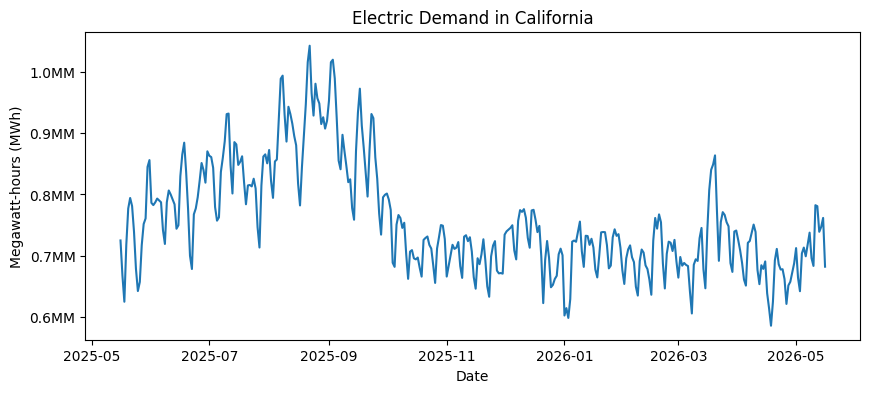

In [82]:
fig, ax = plt.subplots(figsize=(10,4))

ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'{x/1e6:.1f}MM')
)


ax.plot(df["date"], df["e_demand"])
plt.ylabel("Megawatt-hours (MWh)")
plt.xlabel("Date")
plt.title("Electric Demand in California")
plt.show()

19:21:22 - cmdstanpy - INFO - Chain [1] start processing
19:21:22 - cmdstanpy - INFO - Chain [1] done processing


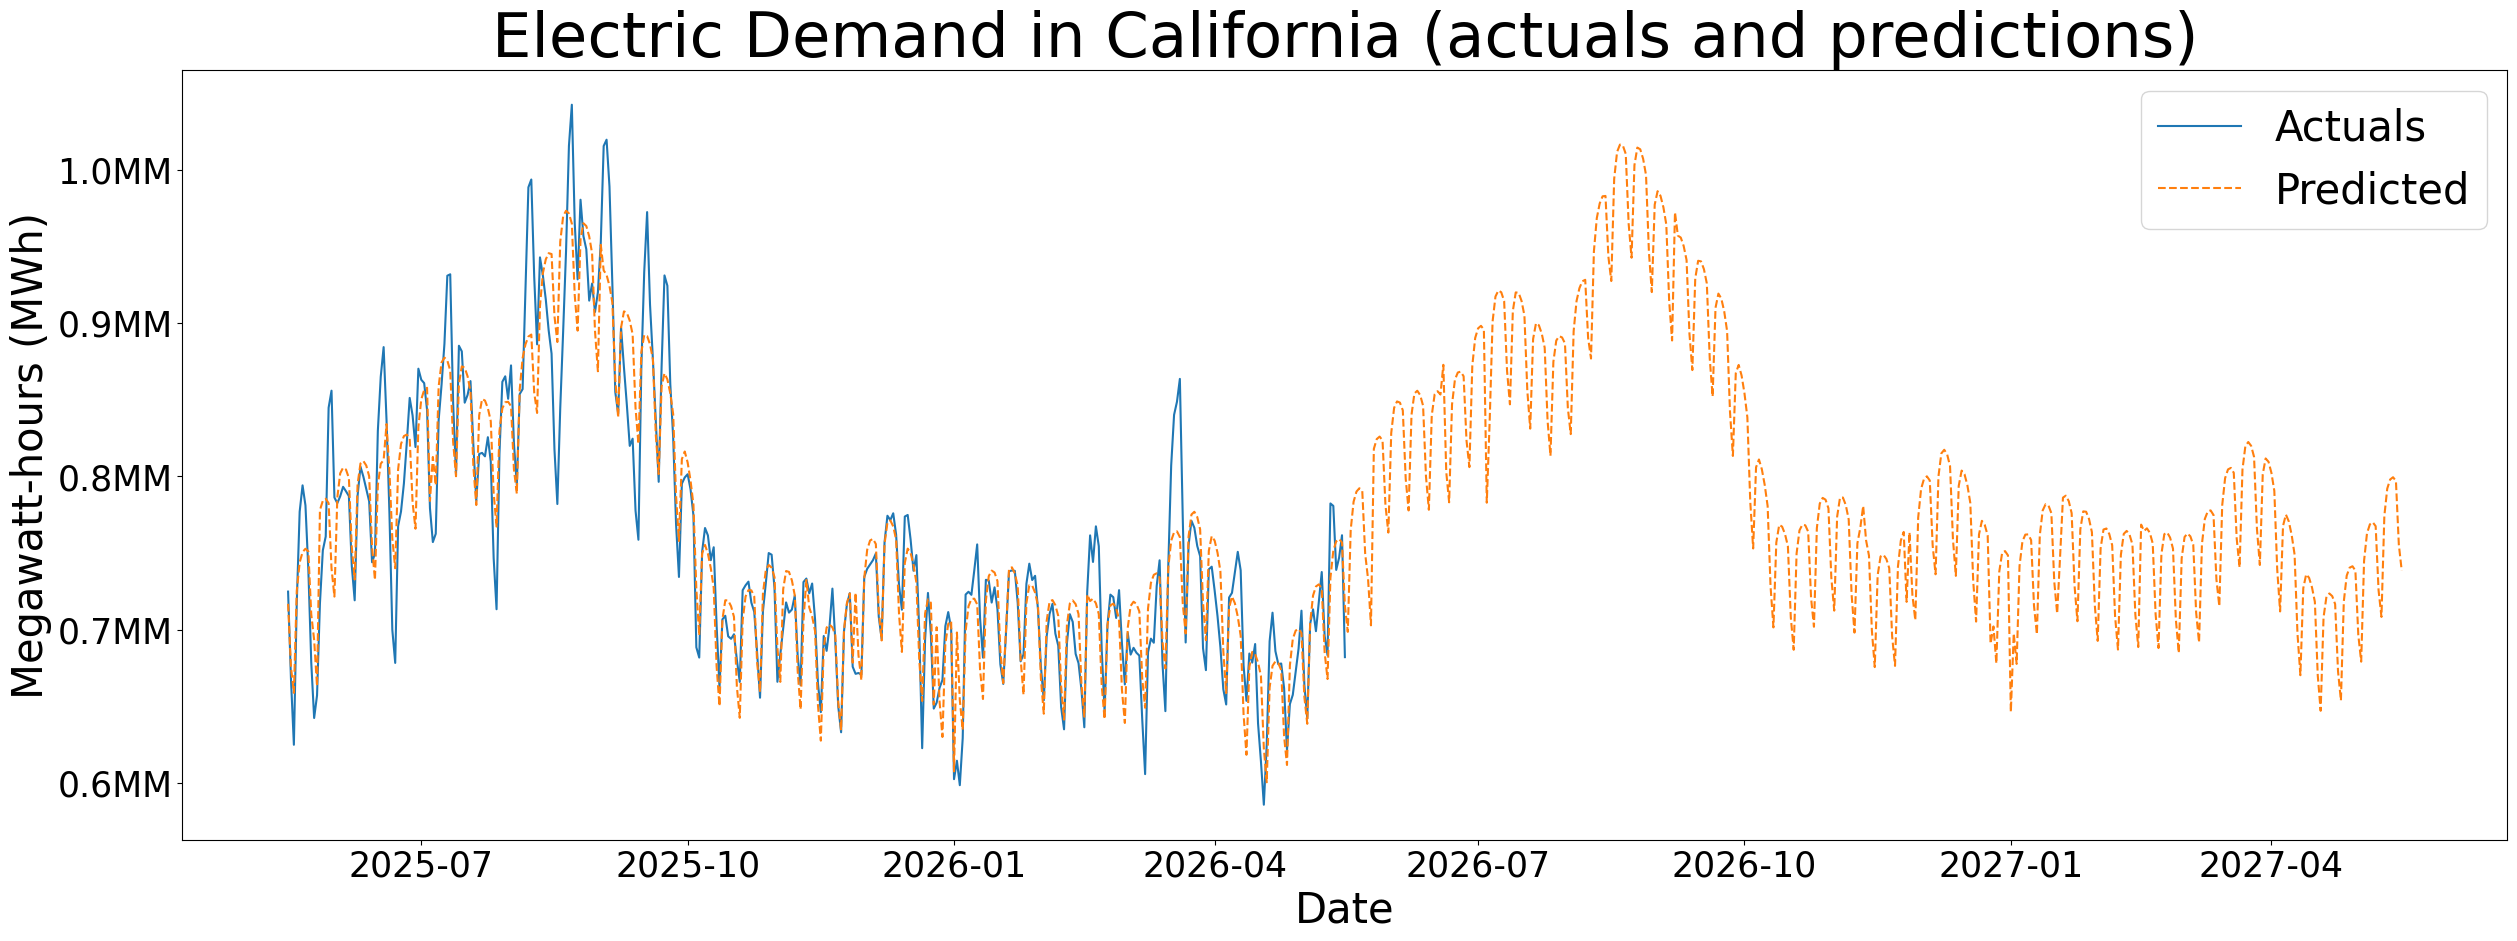

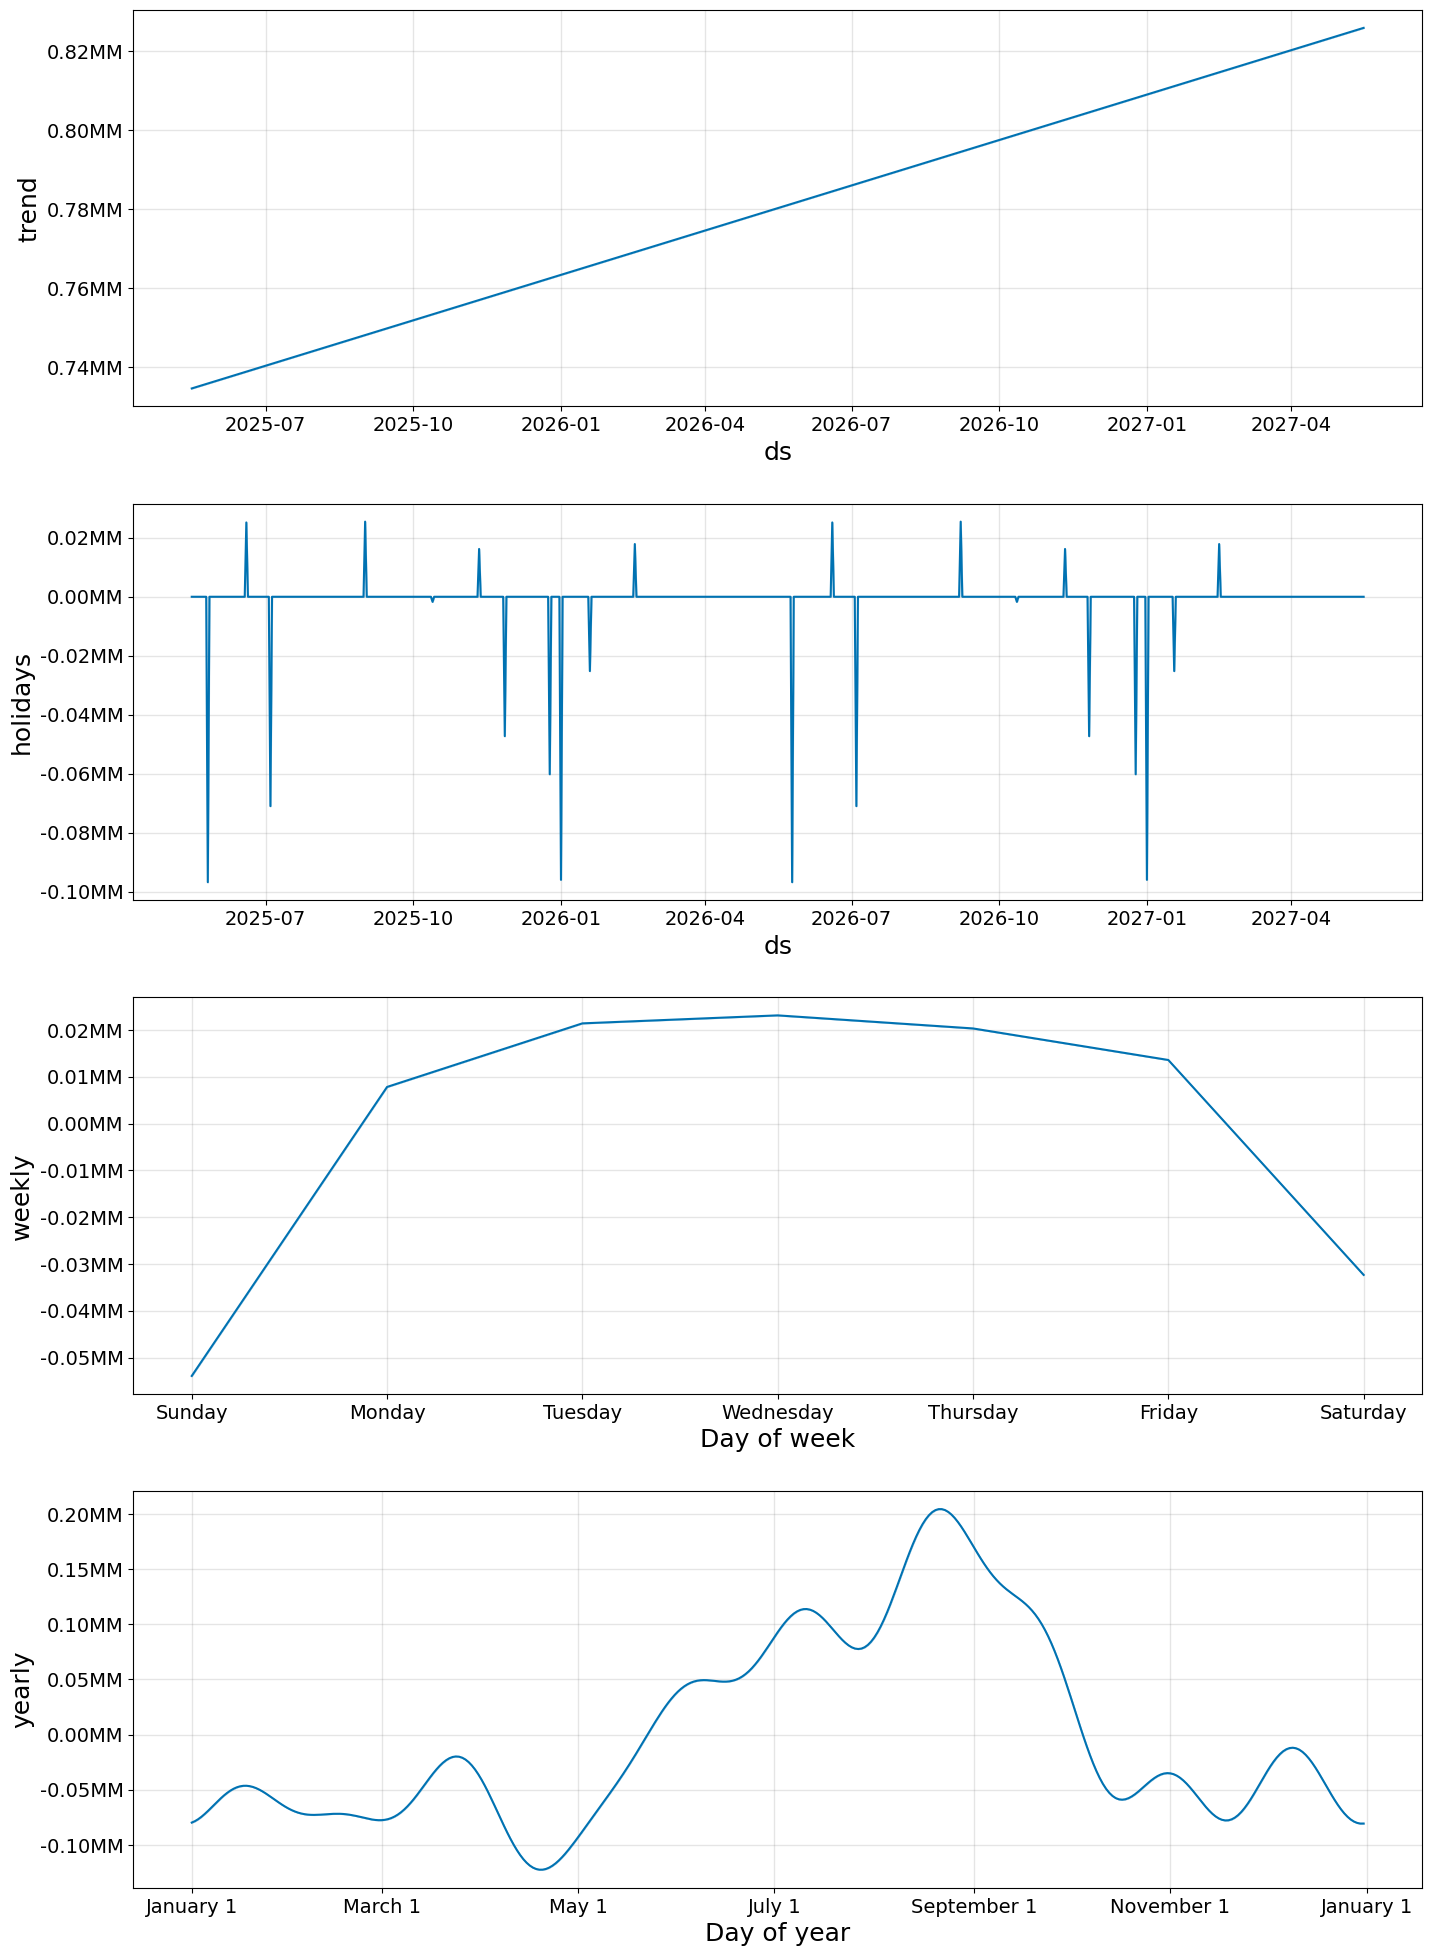

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet

s = df[["date", "e_demand"]].copy()
s = s.rename(columns={"date": "ds", "e_demand": "y"})

s["ds"] = pd.to_datetime(s["ds"])
s["y"] = pd.to_numeric(s["y"], errors="coerce")
s = s.dropna().sort_values("ds")

p = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False
)

# Monthly seasonality
# p.add_seasonality(
#     name="monthly",
#     period=30.5,
#     fourier_order=5
# )

# Quarterly seasonality
# p.add_seasonality(
#     name="quarterly",
#     period=365.25 / 4,
#     fourier_order=5
# )

p.add_country_holidays(country_name="US")

p.fit(s)

future = p.make_future_dataframe(periods=365, freq="D")
forecast = p.predict(future)



fig, ax = plt.subplots(figsize=(30,10))

ax.plot(df["date"], df["e_demand"], label="Actuals")

ax.plot(forecast["ds"], forecast["yhat"], label="Predicted", linestyle="--")

ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'{x/1e6:.1f}MM')
)

plt.legend(fontsize=30)
plt.ylabel("Megawatt-hours (MWh)", fontsize=30)
plt.xlabel("Date", fontsize=30)
plt.title("Electric Demand in California (actuals and predictions)", fontsize=45)
plt.tick_params(axis='both', labelsize=25)
plt.show()

fig2 = p.plot_components(forecast)
fig2.set_size_inches(15, 20)

for ax in fig2.axes:
    ax.yaxis.set_major_formatter(
        mtick.FuncFormatter(lambda x, _: f'{x/1e6:.2f}MM')
    )

    ax.tick_params(axis='both', labelsize=14)

    ax.title.set_fontsize(18)

    ax.xaxis.label.set_size(18)
    ax.yaxis.label.set_size(18)

plt.show()

In [ ]:
forecast.columns

Index(['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper',
       'Christmas Day', 'Christmas Day_lower', 'Christmas Day_upper',
       'Columbus Day', 'Columbus Day_lower', 'Columbus Day_upper',
       'Independence Day', 'Independence Day_lower', 'Independence Day_upper',
       'Independence Day (observed)', 'Independence Day (observed)_lower',
       'Independence Day (observed)_upper',
       'Juneteenth National Independence Day',
       'Juneteenth National Independence Day_lower',
       'Juneteenth National Independence Day_upper', 'Labor Day',
       'Labor Day_lower', 'Labor Day_upper', 'Martin Luther King Jr. Day',
       'Martin Luther King Jr. Day_lower', 'Martin Luther King Jr. Day_upper',
       'Memorial Day', 'Memorial Day_lower', 'Memorial Day_upper',
       'New Year's Day', 'New Year's Day_lower', 'New Year's Day_upper',
       'Thanksgiving Day', 'Thanksgiving Day_lower', 'Thanksgiving Day_upper',
       'Veterans Day', 'Veterans Day_lower', '

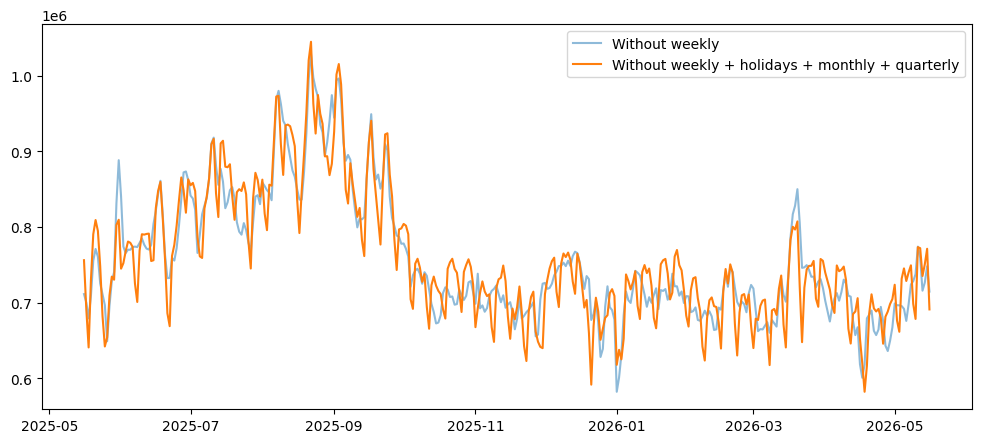

In [ ]:
check = s.merge(
    forecast[["ds", "weekly", "holidays", "monthly", "quarterly"]],
    on="ds",
    how="left"
)


check["y_no_weekly"] = (
    check["y"]
    - check["weekly"].fillna(0)
)

check["y_no_weekly_hol"] = (
    check["y"]
    - check["weekly"].fillna(0)
    - check["holidays"].fillna(0)
)


check["y_no_weekly_hol_mon"] = (
    check["y"]
    - check["weekly"].fillna(0)
    - check["holidays"].fillna(0)
    - check["monthly"].fillna(0)
)


check["y_no_weekly_hol_mon_quar"] = (
    check["y"]
    # - check["weekly"].fillna(0)
    # - check["holidays"].fillna(0)
    - check["monthly"].fillna(0)
    - check["quarterly"].fillna(0)
)

check[["ds", "y", "weekly", "holidays", "monthly", "quarterly", "y_no_weekly", "y_no_weekly_hol", "y_no_weekly_hol_mon", "y_no_weekly_hol_mon_quar"]].head()


plt.figure(figsize=(12, 5))
# plt.plot(check["ds"], check["y"], label="Original", alpha=0.5)
plt.plot(check["ds"], check["y_no_weekly"], label="Without weekly", alpha=0.5)
# plt.plot(check["ds"], check["y_no_weekly_hol"], label="Without weekly + holidays")
# plt.plot(check["ds"], check["y_no_weekly_hol_mon"], label="Without weekly + holidays + monthly")
plt.plot(check["ds"], check["y_no_weekly_hol_mon_quar"], label="Without weekly + holidays + monthly + quarterly")
plt.legend()
plt.show()

In [ ]:
d = df.copy()

d["date"] = pd.to_datetime(d["date"])

d["week_number"] = d["date"].dt.isocalendar().week.astype(int)
d["weekday"] = d["date"].dt.day_name()

d["year"] = d["date"].dt.isocalendar().year.astype(int)

d["week_min_demand"] = d.groupby(["year", "week_number"])["e_demand"].transform("min")

d["e_demand_vs_week_min"] = d["e_demand"] / d["week_min_demand"]

d[["date", "year", "week_number", "weekday", "e_demand", "week_min_demand", "e_demand_vs_week_min"]].head()

,date,year,week_number,weekday,e_demand,week_min_demand,e_demand_vs_week_min
0,2025-05-16,2025,20,Friday,724914,625023,1.159820
1,2025-05-17,2025,20,Saturday,667758,625023,1.068373
2,2025-05-18,2025,20,Sunday,625023,625023,1.000000
3,2025-05-19,2025,21,Monday,717810,642490,1.117231
4,2025-05-20,2025,21,Tuesday,777017,642490,1.209384


C:\Users\snayt\AppData\Local\Temp\ipykernel_18192\3057193785.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


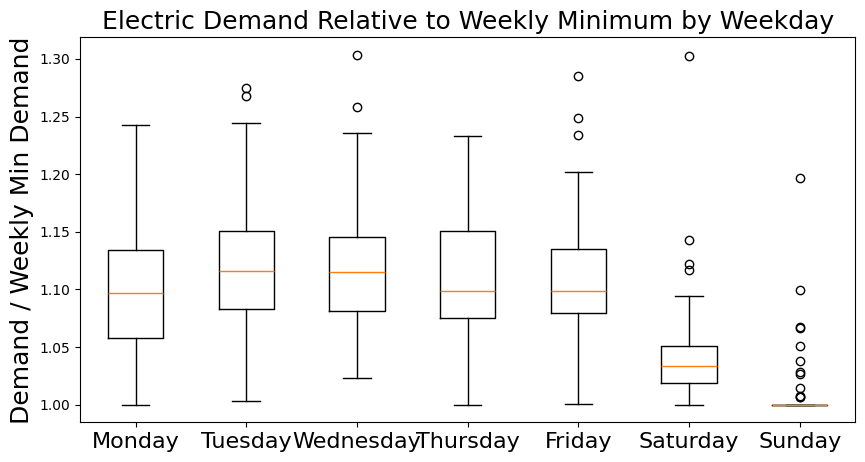

In [114]:
import matplotlib.pyplot as plt

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

data = [
    d.loc[d["weekday"] == day, "e_demand_vs_week_min"]
    for day in weekday_order
]

plt.figure(figsize=(10, 5))

plt.boxplot(
    data,
    labels=weekday_order
)

plt.ylabel("Demand / Weekly Min Demand", fontsize=18)
plt.title("Electric Demand Relative to Weekly Minimum by Weekday", fontsize=18)

plt.tick_params(axis='x', labelsize=16)

plt.show()

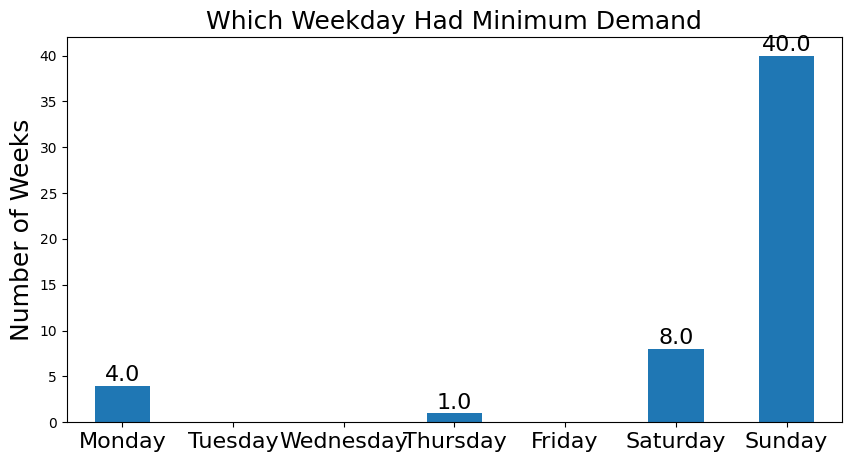

In [ ]:
import matplotlib.pyplot as plt

week_min_day = (
    d.loc[
        d.groupby(["year", "week_number"])["e_demand"].idxmin(),
        ["year", "week_number", "weekday"]
    ]
    .rename(columns={"weekday": "min_weekday"})
)

weekday_counts = (
    week_min_day["min_weekday"]
    .value_counts()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

plt.figure(figsize=(10, 5))

ax = weekday_counts.plot(kind="bar")
plt.xticks(rotation=0)

for i, v in enumerate(weekday_counts.values):
    ax.text(i, v + 0.5, str(v), ha="center", fontsize=16)


plt.ylabel("Number of Weeks", fontsize=18)
plt.xlabel("")
plt.title("Which Weekday Had Minimum Demand", fontsize=18)
plt.tick_params(axis='x', labelsize=16)

plt.show()